## 1. Setup and Loading of data 

In [2]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from core.data import load_from_kaggle

# Styling für bessere Visualisierungen
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['figure.dpi'] = 100



In [2]:
# ===== DATASET-LINK =====
full_link = r"https://www.kaggle.com/datasets/gagandeep16/car-sales"
dataset_link = full_link.split("/datasets/")[-1]
# ======================================

destination = "../data/raw"
dataset_name = dataset_link.split("/")[-1]

print(f"📦 Loading Dataset: {dataset_name}")
files = load_from_kaggle(
    dataset_link=dataset_link, 
    destination=destination,
)

print(f"✅ {len(files)} files found:")
for i, file in enumerate(files, 1):
    print(f"   {i}. {file}")


📦 Loading Dataset: car-sales
Destination directory '../data/raw\car-sales' already exists with files. Skipping download (replace=False).
✅ 1 files found:
   1. Car_sales.csv




## 2. Reading Data & Initial Inspection



In [3]:

# Load the first CSV file
file_path = "/".join([destination, dataset_name, files[0]])
df = pd.read_csv(file_path)

print(f"📊 Loaded File: {files[0]}")
print(f"📏 Shape: {df.shape[0]:,} Rows × {df.shape[1]} Columns\n")

df.sample(10)

📊 Loaded File: Car_sales.csv
📏 Shape: 157 Rows × 16 Columns



,Manufacturer,Model,Sales_in_thousands,__year_resale_value,Vehicle_type,Price_in_thousands,Engine_size,Horsepower,Wheelbase,Width,Length,Curb_weight,Fuel_capacity,Fuel_efficiency,Latest_Launch,Power_perf_factor
9,BMW,528i,17.527,36.125,Passenger,38.900,2.8,193.0,111.4,70.9,188.0,3.472,18.5,25.0,4/4/2011,83.998724
79,Mitsubishi,Mirage,26.232,8.325,Passenger,13.987,1.8,113.0,98.4,66.5,173.6,2.250,13.2,30.0,4/23/2012,45.832181
147,Volkswagen,Passat,51.102,16.725,Passenger,21.200,1.8,150.0,106.4,68.5,184.1,3.043,16.4,27.0,10/30/2012,61.701381
51,Ford,Crown Victoria,63.403,14.210,Passenger,22.195,4.6,200.0,114.7,78.2,212.0,3.908,19.0,21.0,9/26/2011,80.499537
27,Chevrolet,Impala,107.995,NaN,Passenger,18.890,3.4,180.0,110.5,73.0,200.0,3.389,17.0,27.0,6/18/2011,71.838039
129,Saturn,SL,80.620,9.200,Passenger,10.685,1.9,100.0,102.4,66.4,176.9,2.332,12.1,33.0,8/16/2012,39.986425
150,Volkswagen,Beetle,49.463,NaN,Passenger,15.900,2.0,115.0,98.9,67.9,161.1,2.769,14.5,26.0,10/20/2011,47.329632
73,Lexus,LS400,6.375,40.375,Passenger,54.005,4.0,290.0,112.2,72.0,196.7,3.890,22.5,22.0,3/29/2012,124.446716
85,Mitsubishi,Montero Sport,39.348,13.880,Car,22.527,3.0,173.0,107.3,66.7,178.3,3.510,19.5,20.0,5/18/2012,70.660942
111,Oldsmobile,Aurora,14.690,19.890,Passenger,36.229,4.0,250.0,113.8,74.4,205.4,3.967,18.5,22.0,2/18/2011,103.441693




---

## 3. Data Quality & Structure



In [4]:

print("=" * 80)
print("📋 DATA OVERVIEW")
print("=" * 80)

# Basic Statistics
print(f"\n🔢 Dimensions: {df.shape[0]:,} Rows × {df.shape[1]} Columns")
print(f"🔄 Duplicate percentage: {df.duplicated().sum():,} ({df.duplicated().sum()/len(df)*100:.2f}%)")
print(f"💾 Memory Usage: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")


📋 DATA OVERVIEW

🔢 Dimensions: 157 Rows × 16 Columns
🔄 Duplicate percentage: 0 (0.00%)
💾 Memory Usage: 0.05 MB


In [5]:
# Detailed Column Overview
column_info = pd.DataFrame({
    "Data types": df.dtypes,
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df) * 100).round(2),
    "Unique Values": df.nunique(),
    "Sample Values": [df[col].dropna().sample(min(3, df[col].notna().sum())).tolist() 
                      if df[col].notna().sum() > 0 else [] 
                      for col in df.columns]
})

column_info = column_info.sort_values("Missing Percentage", ascending=False)
column_info


,Data types,Missing Values,Missing Percentage,Unique Values,Sample Values
__year_resale_value,float64,36,22.93,117,"[12.64, 19.875, 67.55]"
Fuel_efficiency,float64,3,1.91,20,"[23.0, 16.0, 23.0]"
Curb_weight,float64,2,1.27,147,"[2.975, 2.99, 4.121]"
Price_in_thousands,float64,2,1.27,152,"[13.987, 28.34, 16.875]"
Power_perf_factor,float64,2,1.27,154,"[103.4416926, 67.54415494, 92.85412522]"
Wheelbase,float64,1,0.64,88,"[97.0, 117.7, 102.4]"
Engine_size,float64,1,0.64,31,"[2.0, 1.8, 1.9]"
Horsepower,float64,1,0.64,66,"[220.0, 227.0, 300.0]"
Length,float64,1,0.64,127,"[190.1, 200.7, 186.3]"
Width,float64,1,0.64,78,"[70.3, 78.8, 67.9]"




---

## 4. Analyze Numerical Variables



In [6]:

# Analyze Numerical Variables
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

if numeric_cols:
    print(f"📊 {len(numeric_cols)} numeric columns found\n")
    display(df[numeric_cols].describe().round(2).T)
else:
    print("⚠️ No numeric columns found")



📊 12 numeric columns found



,count,mean,std,min,25%,50%,75%,max
Sales_in_thousands,157.0,53.00,68.03,0.11,14.11,29.45,67.96,540.56
__year_resale_value,121.0,18.07,11.45,5.16,11.26,14.18,19.88,67.55
Price_in_thousands,155.0,27.39,14.35,9.24,18.02,22.80,31.95,85.50
Engine_size,156.0,3.06,1.04,1.00,2.30,3.00,3.58,8.00
Horsepower,156.0,185.95,56.70,55.00,149.50,177.50,215.00,450.00
Wheelbase,156.0,107.49,7.64,92.60,103.00,107.00,112.20,138.70
Width,156.0,71.15,3.45,62.60,68.40,70.55,73.43,79.90
Length,156.0,187.34,13.43,149.40,177.58,187.90,196.12,224.50
Curb_weight,155.0,3.38,0.63,1.90,2.97,3.34,3.80,5.57
Fuel_capacity,156.0,17.95,3.89,10.30,15.80,17.20,19.58,32.00


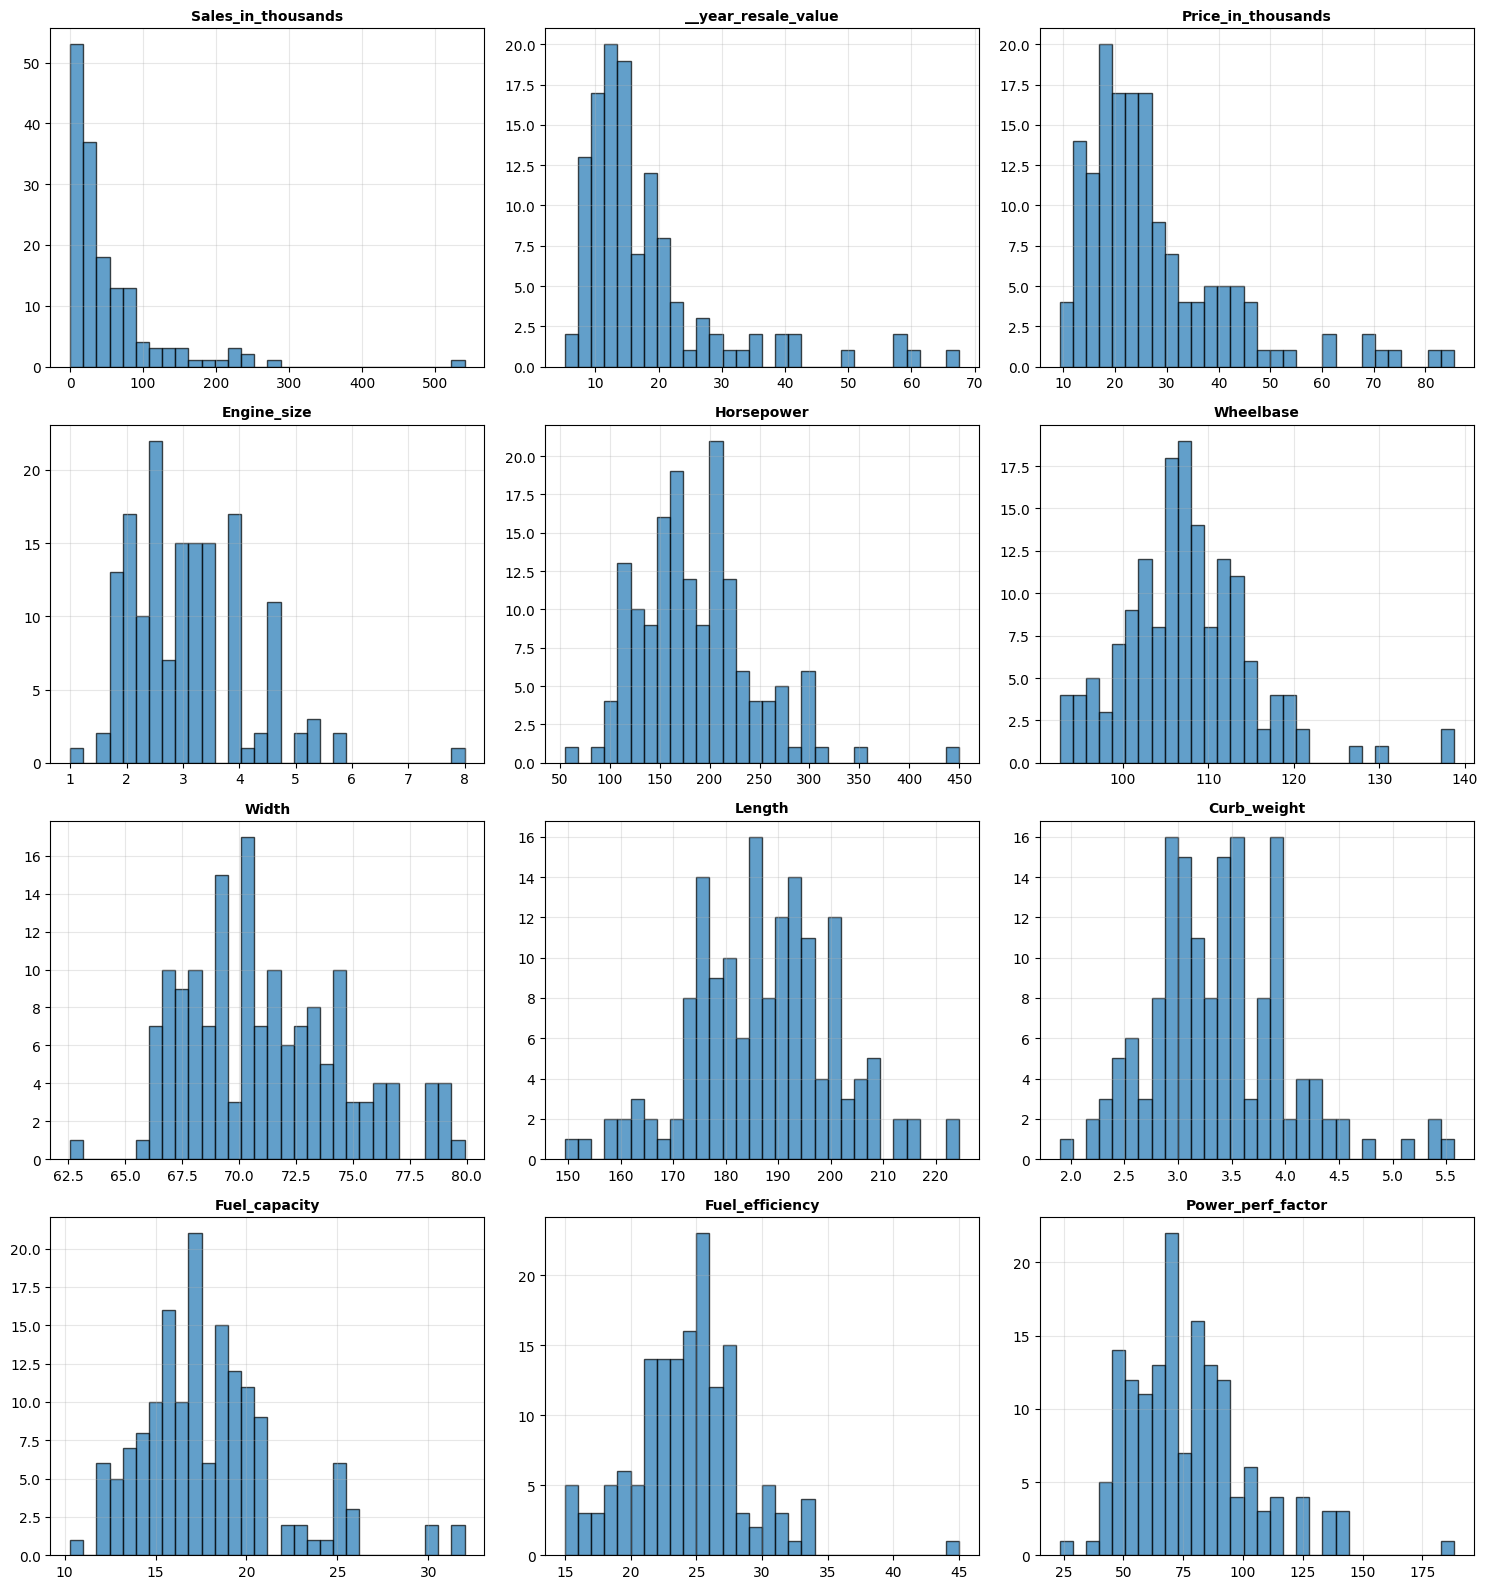

In [ ]:
# Distributions of Numerical Variables
if numeric_cols:
    n_cols = min(3, len(numeric_cols))
    n_rows = (len(numeric_cols) + n_cols - 1) // n_cols
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 4))
    axes = axes.flatten() if len(numeric_cols) > 1 else [axes]
    
    for idx, col in enumerate(numeric_cols):
        ax = axes[idx]
        df[col].hist(bins=30, ax=ax, edgecolor='black', alpha=0.7)
        ax.set_title(f'{col}', fontsize=10, fontweight='bold')
        ax.grid(alpha=0.3)
    
    # Hide empty subplots
    for idx in range(len(numeric_cols), len(axes)):
        axes[idx].axis('off')
    
    plt.tight_layout()
    plt.show()




---

## 5. Analyze Categorical Variables



In [12]:

# Identify Categorical Columns
categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

if categorical_cols:
    print(f"🏷️ {len(categorical_cols)} categorical columns found\n")
    
    cat_summary = pd.DataFrame({
        "Column": categorical_cols,
        "Unique Values": [df[col].nunique() for col in categorical_cols],
        "Most Frequent Values": [df[col].value_counts().head(3).to_dict() for col in categorical_cols]
    })
    
    display(cat_summary)
else:
    print("⚠️ No categorical columns found")


🏷️ 4 categorical columns found



,Column,Unique Values,Most Frequent Values
0,Manufacturer,30,"{'Ford': 11, 'Dodge': 11, 'Chevrolet': 9}"
1,Model,156,"{'Neon': 2, 'Integra': 1, 'CL': 1}"
2,Vehicle_type,2,"{'Passenger': 116, 'Car': 41}"
3,Latest_Launch,130,"{'1/29/2012': 2, '1/4/2012': 2, '8/31/2011': 2}"


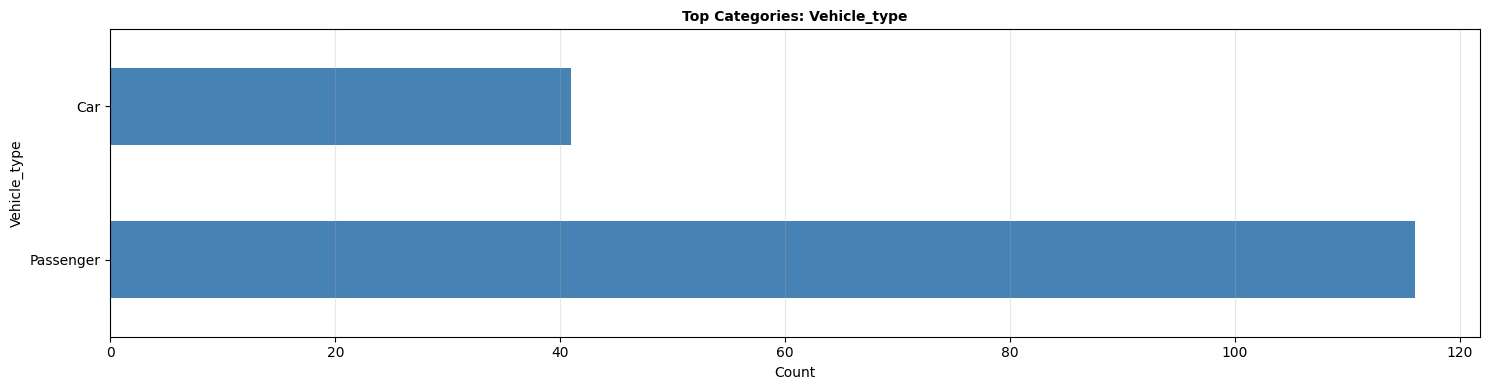

In [13]:
# Visualize top categories (for columns with few unique values)
if categorical_cols:
    low_cardinality_cols = [col for col in categorical_cols if df[col].nunique() <= 20]

    if low_cardinality_cols:
        n_cols = min(2, len(low_cardinality_cols))
        n_rows = (len(low_cardinality_cols) + n_cols - 1) // n_cols

        fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 4))
        axes = axes.flatten() if len(low_cardinality_cols) > 1 else [axes]

        for idx, col in enumerate(low_cardinality_cols):
            ax = axes[idx]
            value_counts = df[col].value_counts().head(10)
            value_counts.plot(kind='barh', ax=ax, color='steelblue')
            ax.set_title(f'Top Categories: {col}', fontsize=10, fontweight='bold')
            ax.set_xlabel('Count')
            ax.grid(alpha=0.3, axis='x')

        # Hide empty subplots
        for idx in range(len(low_cardinality_cols), len(axes)):
            axes[idx].axis('off')

        plt.tight_layout()
        plt.show()




---

## 6. Correlation Analysis



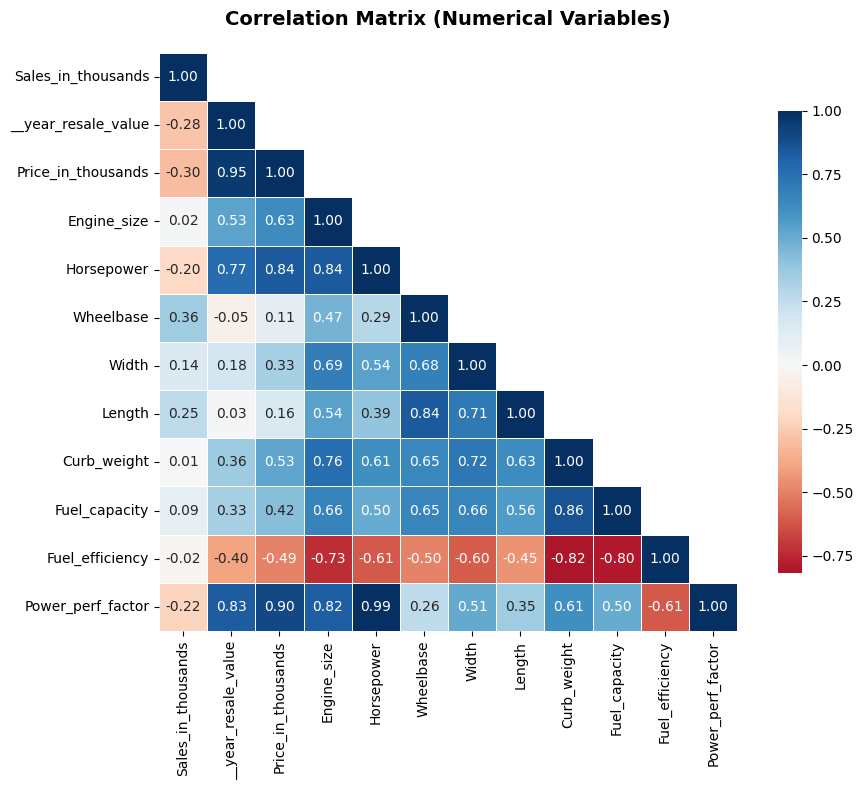


🔗 Strongest Correlations (|r| > 0.5):



,Variable 1,Variable 2,Correlation
18,Horsepower,Power_perf_factor,0.992994
0,__year_resale_value,Price_in_thousands,0.953840
7,Price_in_thousands,Power_perf_factor,0.897945
30,Curb_weight,Fuel_capacity,0.863968
5,Price_in_thousands,Horsepower,0.839744
20,Wheelbase,Length,0.839639
8,Engine_size,Horsepower,0.837360
3,__year_resale_value,Power_perf_factor,0.827123
14,Engine_size,Power_perf_factor,0.818528
31,Curb_weight,Fuel_efficiency,-0.818402


In [14]:

if len(numeric_cols) > 1:
    # Correlation matrix
    corr_matrix = df[numeric_cols].corr()

    # Heatmap
    fig, ax = plt.subplots(figsize=(10, 8), dpi=100)
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)  # Mask upper triangular matrix

    sns.heatmap(
        corr_matrix,
        mask=mask,
        annot=True,
        fmt='.2f',
        cmap='RdBu',
        center=0,
        square=True,
        linewidths=0.5,
        cbar_kws={"shrink": 0.8},
        ax=ax
    )

    ax.set_title(
        'Correlation Matrix (Numerical Variables)',
        fontsize=14,
        fontweight='bold',
        pad=20
    )
    plt.tight_layout()
    plt.show()

    # Find strongest correlations
    print("\n🔗 Strongest Correlations (|r| > 0.5):\n")

    corr_pairs = []
    for i in range(len(corr_matrix.columns)):
        for j in range(i + 1, len(corr_matrix.columns)):
            if abs(corr_matrix.iloc[i, j]) > 0.5:
                corr_pairs.append({
                    'Variable 1': corr_matrix.columns[i],
                    'Variable 2': corr_matrix.columns[j],
                    'Correlation': corr_matrix.iloc[i, j]
                })

    if corr_pairs:
        corr_df = pd.DataFrame(corr_pairs).sort_values(
            'Correlation',
            key=abs,
            ascending=False
        )
        display(corr_df)
    else:
        print("No strong correlations found.")
else:
    print("⚠️ Not enough numerical variables for correlation analysis")



---

## 7. Visualize Missing Values



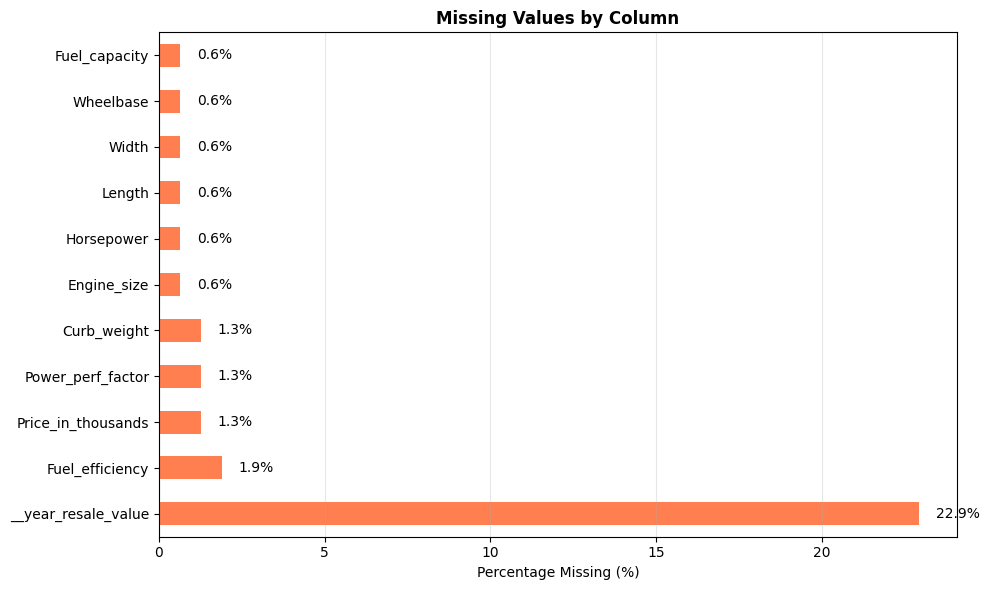

In [15]:

missing_data = df.isnull().sum()
missing_data = missing_data[missing_data > 0].sort_values(ascending=False)

if len(missing_data) > 0:
    fig, ax = plt.subplots(figsize=(10, max(6, len(missing_data) * 0.4)))

    missing_percent = (missing_data / len(df) * 100)
    missing_percent.plot(kind='barh', ax=ax, color='coral')

    ax.set_title('Missing Values by Column', fontsize=12, fontweight='bold')
    ax.set_xlabel('Percentage Missing (%)')
    ax.grid(alpha=0.3, axis='x')

    # Add values as text labels
    for i, v in enumerate(missing_percent):
        ax.text(v + 0.5, i, f'{v:.1f}%', va='center')

    plt.tight_layout()
    plt.show()
else:
    print("✅ No missing values in the dataset!")




---

## 8. Summary & Evaluation



In [16]:

print("=" * 80)
print("📝 DATASET EVALUATION FOR PORTFOLIO PROJECT")
print("=" * 80)

# Calculate quality criteria
data_quality = {
    "Dataset Size": "✅ Good" if len(df) > 5_000 else "⚠️ Small" if len(df) > 1_000 else "❌ Too Small",
    "Completeness": f"✅ {(1 - df.isnull().sum().sum() / (df.shape[0] * df.shape[1])) * 100:.1f}%",
    "Duplicates": "✅ None" if df.duplicated().sum() == 0 else f"⚠️ {df.duplicated().sum()} found",
    "Variable Diversity": f"{'✅' if df.shape[1] >= 10 else '⚠️'} {df.shape[1]} columns",
    "Numerical Features": f"{'✅' if len(numeric_cols) >= 5 else '⚠️'} {len(numeric_cols)} columns",
    "Categorical Features": f"{'✅' if len(categorical_cols) >= 1 else '⚠️'} {len(categorical_cols)} columns"
}

for criterion, status in data_quality.items():
    print(f"{criterion:.<30} {status}")

print("\n" + "=" * 80)
print("💡 RECOMMENDATION:")
print("=" * 80)

score = sum([
    len(df) > 5000,
    df.isnull().sum().sum() / (df.shape[0] * df.shape[1]) < 0.1,
    df.duplicated().sum() < len(df) * 0.05,
    df.shape[1] >= 10,
    len(numeric_cols) >= 5
])

if score >= 4:
    print("✅ EXCELLENT - This dataset is highly suitable for a portfolio project!")
elif score >= 3:
    print("👍 GOOD - This dataset is suitable for a portfolio project.")
else:
    print("⚠️ LIMITED - Consider whether this dataset is sufficient for your project.")

print("\n📌 Next Steps:")
print("   1. Define your research question")
print("   2. Identify relevant features")
print("   3. Plan your analysis strategy")
print("   4. Start feature engineering and modeling")

📝 DATASET EVALUATION FOR PORTFOLIO PROJECT
Dataset Size.................. ❌ Too Small
Completeness.................. ✅ 98.0%
Duplicates.................... ✅ None
Variable Diversity............ ✅ 16 columns
Numerical Features............ ✅ 12 columns
Categorical Features.......... ✅ 4 columns

💡 RECOMMENDATION:
✅ EXCELLENT - This dataset is highly suitable for a portfolio project!

📌 Next Steps:
   1. Define your research question
   2. Identify relevant features
   3. Plan your analysis strategy
   4. Start feature engineering and modeling
